In [509]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, f1_score 
from sklearn.metrics import recall_score, precision_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import make_scorer


from sklearn.preprocessing import MinMaxScaler

from sklearn.tree import export_graphviz
from six import StringIO  
from IPython.display import Image  
import pydotplus

pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Train a model on tips dataset

In [510]:
tips = sns.load_dataset('tips')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.9900,1.0100,Female,No,Sun,Dinner,2
1,10.3400,1.6600,Male,No,Sun,Dinner,3
2,21.0100,3.5000,Male,No,Sun,Dinner,3
3,23.6800,3.3100,Male,No,Sun,Dinner,2
4,24.5900,3.6100,Female,No,Sun,Dinner,4


In [511]:
tips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [512]:
tips.dropna(inplace = True)

In [513]:
tips.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

## Define the target and the features

Machine learning models need numerical inputs, so we have to turn our categorical text data like 'smoker', 'day', and 'time' into binary columns with 1s and 0s. This is done using One-Hot Encoding. By setting drop_first=True, we avoid the Dummy Variable Trap. Dropping one category ensures our features remain independent. 

In [514]:
# dtype=int ensures we get 0s and 1s instead of True/False booleans
dummy_columns = pd.get_dummies(tips[['smoker', 'day', 'time']], dtype=int, drop_first = True)
dummy_columns

,smoker_No,day_Fri,day_Sat,day_Sun,time_Dinner
0,1,0,0,1,1
1,1,0,0,1,1
2,1,0,0,1,1
3,1,0,0,1,1
4,1,0,0,1,1
...,...,...,...,...,...
239,1,0,1,0,1
240,0,0,1,0,1
241,0,0,1,0,1
242,1,0,1,0,1


You might notice that 'day_Thur' does not appear in the output. It is not deleted. Instead, it serves as our reference state. When 'day_Fri', 'day_Sat', and 'day_Sun' are all 0 for a row, the model figures out that the day is Thursday.

In [515]:
tips_dummies = pd.concat([tips, dummy_columns], axis = 1)
tips_dummies.head()

,total_bill,tip,sex,smoker,day,time,size,smoker_No,day_Fri,day_Sat,day_Sun,time_Dinner
0,16.9900,1.0100,Female,No,Sun,Dinner,2,1,0,0,1,1
1,10.3400,1.6600,Male,No,Sun,Dinner,3,1,0,0,1,1
2,21.0100,3.5000,Male,No,Sun,Dinner,3,1,0,0,1,1
3,23.6800,3.3100,Male,No,Sun,Dinner,2,1,0,0,1,1
4,24.5900,3.6100,Female,No,Sun,Dinner,4,1,0,0,1,1


In [516]:
tips_dummies.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size',
       'smoker_No', 'day_Fri', 'day_Sat', 'day_Sun', 'time_Dinner'],
      dtype='object')

In [517]:
y = tips_dummies['sex']
X = tips_dummies.drop(columns = ['sex', 'smoker', 'day', 'time'])

In [518]:
X.columns

Index(['total_bill', 'tip', 'size', 'smoker_No', 'day_Fri', 'day_Sat',
       'day_Sun', 'time_Dinner'],
      dtype='object')

In [519]:
y.value_counts()

sex
Male      157
Female     87
Name: count, dtype: int64

In [520]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 0, stratify = y)

In [521]:
metrics_leaderboard = pd.DataFrame(columns=[
    'Model', 
    'Train Acc', 'Test Acc', 
    'Train Prec', 'Test Prec', 
    'Train Rec', 'Test Rec', 
    'Train F1', 'Test F1',
    'CV F1 Mean', 'CV F1 Std'
])

In [522]:
def log_and_display_metrics(
        model_name, 
        model, 
        X_train, 
        y_train, 
        X_test, 
        y_test, 
        pos_label='Female', 
        cv=5
        ):
    global metrics_leaderboard
    
  
    f1_scorer = make_scorer(f1_score, pos_label=pos_label, zero_division=0)
    
    cv_scores = cross_val_score(model, X_train, y_train, scoring=f1_scorer, cv=cv)
    
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    new_row = pd.DataFrame({
        'Model': [model_name],
        'Train Acc': [round(accuracy_score(y_train, y_train_pred), 4)],
        'Test Acc': [round(accuracy_score(y_test, y_test_pred), 4)],
        'Train Prec': [round(precision_score(y_train, y_train_pred, pos_label=pos_label, zero_division=0), 4)],
        'Test Prec': [round(precision_score(y_test, y_test_pred, pos_label=pos_label, zero_division=0), 4)],
        'Train Rec': [round(recall_score(y_train, y_train_pred, pos_label=pos_label, zero_division=0), 4)],
        'Test Rec': [round(recall_score(y_test, y_test_pred, pos_label=pos_label, zero_division=0), 4)],
        'Train F1': [round(f1_score(y_train, y_train_pred, pos_label=pos_label, zero_division=0), 4)],
        'Test F1': [round(f1_score(y_test, y_test_pred, pos_label=pos_label, zero_division=0), 4)],
        'CV F1 Mean': [round(cv_scores.mean(), 4)],
        'CV F1 Std': [round(cv_scores.std(), 4)]
    })
    
    metrics_leaderboard = pd.concat([metrics_leaderboard, new_row], ignore_index=True)
    display(metrics_leaderboard)

In [523]:
def plot_the_test_results(X_test, y_test, y_predict):
    POS_LABEL = "Female"
    tp_mask = (y_test == POS_LABEL) & (y_predict == POS_LABEL)
    fp_mask = (y_test != POS_LABEL) & (y_predict == POS_LABEL)
    tn_mask = (y_test != POS_LABEL) & (y_predict != POS_LABEL)
    fn_mask = (y_test == POS_LABEL) & (y_predict != POS_LABEL)

    X_test_array = np.array(X_test)
    
    tp_data = X_test_array[tp_mask]
    fp_data = X_test_array[fp_mask]
    tn_data = X_test_array[tn_mask]
    fn_data = X_test_array[fn_mask]

    feature_names = X.columns[:2]
    
    f, ax = plt.subplots(figsize=(8, 7))
    ax.scatter(tn_data[:, 0], tn_data[:, 1], color='green', marker='o', s=60, label='TN: Correct Male', alpha=0.6)
    ax.scatter(tp_data[:, 0], tp_data[:, 1], color='blue', marker='o', s=60, label='TP: Correct Female', alpha=0.6)
    ax.scatter(fn_data[:, 0], fn_data[:, 1], color='red', marker='X', s=100, label='FN: Missed Female', alpha=0.6)
    ax.scatter(fp_data[:, 0], fp_data[:, 1], color='orange', marker='X', s=80, label='FP: Incorrect Female', alpha=0.6)

    ax.set_title(f"Model Classification Performance")
    ax.set_xlabel(f"{feature_names[0]}")
    ax.set_ylabel(f"{feature_names[1]}")
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(title="Prediction Status", loc='best')
    
    plt.show()

In [524]:
def plot_confusion_matrices(model_name, y_train_true, y_train_pred, y_test_true, y_test_pred, labels=['Male', 'Female']):
    
    conf_mx_train = confusion_matrix(y_train_true, y_train_pred, labels=labels)
    conf_mx_test = confusion_matrix(y_test_true, y_test_pred, labels=labels)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    plt.subplots_adjust(wspace=0.3)
    
    sns.heatmap(conf_mx_train, annot=True, fmt="d", cbar=False, 
                xticklabels=labels, yticklabels=labels, ax=ax1)
    ax1.set_title(f'{model_name} - Training Data')
    ax1.set_xlabel('Predicted')
    ax1.set_ylabel('Actual')
    ax1.xaxis.tick_top()
    ax1.xaxis.set_label_position('top')
    
    sns.heatmap(conf_mx_test, annot=True, fmt="d", cbar=False, cmap="Oranges", 
                xticklabels=labels, yticklabels=labels, ax=ax2)
    ax2.set_title(f'{model_name} - Testing Data')
    ax2.set_xlabel('Predicted')
    ax2.set_ylabel('Actual')
    ax2.xaxis.tick_top()
    ax2.xaxis.set_label_position('top')
    
    plt.show()

# Tuned Decision Tree

- **criterion**: {"gini","entropy"}
- **max_depth**: The hard stop for tree growth. 

1. A tree that is too deep will perfectly memorise the training noise (High Variance/Overfitting)
2. A tree that is too shallow will miss complex patterns (High Bias/Underfitting).

- **splitter**: {"best"/"random"}
- **min_samples_leaf**: Default = 1. The minimum number of data points allowed in a final decision bucket. Raising this value above the default of 1 stops the model from making overly specific rules for single outliers. This smooths predictions and encourages the model to generalise.
- **min_samples_split**: Default = 2. The minimum number of samples required to split an internal node
- **class_weight**: dict, list of dict or “balanced”, default=None. Weights associated with classes in the form {class_label: weight}.  By setting this to 'balanced', we force the tree to heavily penalise errors on our minority 'Female' class.


More parameters: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

In [525]:
dt = DecisionTreeClassifier(random_state = 0,
                             criterion = 'entropy', 
                            max_depth = 5, 
                            class_weight = 'balanced', 
                            min_samples_leaf = 5) 

Notice that we pass the unscaled X_train data to the Decision Tree, not the X_norm_train data we used for KNN and Logistic Regression. Why? Decision Trees do not calculate distances. They make splitting decisions based on logical thresholds (e.g., "Is total_bill > 15?"). As a result, feature scaling does not affect them.

In [526]:
dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

In [527]:
y_predict = dt.predict(X_test)
y_train_estimated = dt.predict(X_train)

In [528]:
log_and_display_metrics('DT tuned', dt, X_train, y_train, X_test, y_test)

/var/folders/j4/jj1yg9_x1k1__yk65jj_x9c40000gn/T/ipykernel_13798/209274663.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  metrics_leaderboard = pd.concat([metrics_leaderboard, new_row], ignore_index=True)


,Model,Train Acc,Test Acc,Train Prec,Test Prec,Train Rec,Test Rec,Train F1,Test F1,CV F1 Mean,CV F1 Std
0,DT tuned,0.6647,0.5000,0.5222,0.3590,0.7705,0.5385,0.6225,0.4308,0.4294,0.1133


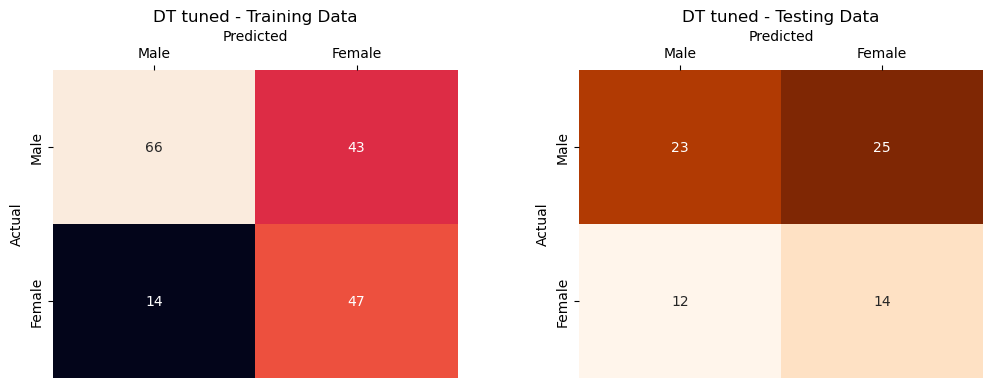

In [529]:
plot_confusion_matrices('DT tuned', y_train, y_train_estimated, y_test, y_predict, labels=['Male', 'Female'])

In the Testing Data, the model successfully caught 14 of the 26 actual females (a Recall of 54%). To catch those 14 females, the model sacrificed its accuracy on males. It incorrectly labelled 25 actual males as females (False Positives).

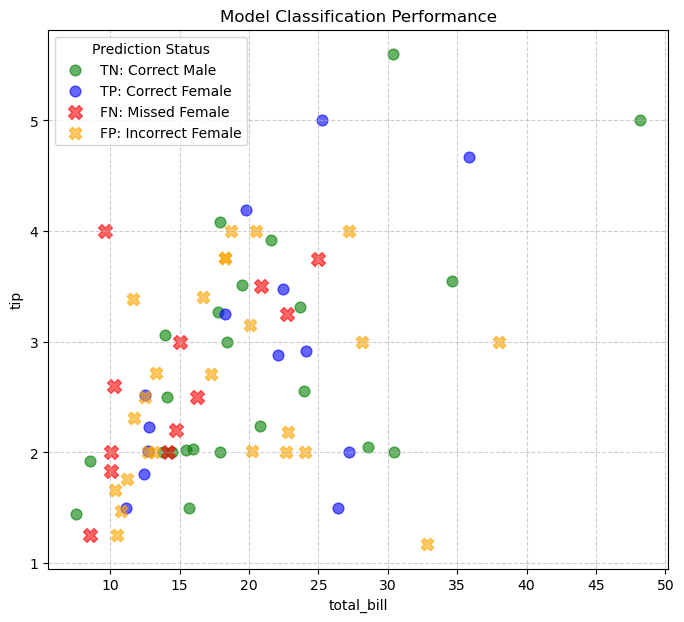

In [530]:
plot_the_test_results(X_test, y_test, y_predict)

The classes are heavily overlapping. This overlap physically prevents the model from drawing a clean decision boundary, leading to the massive spray of red and orange "X" error markers across the entire plot.

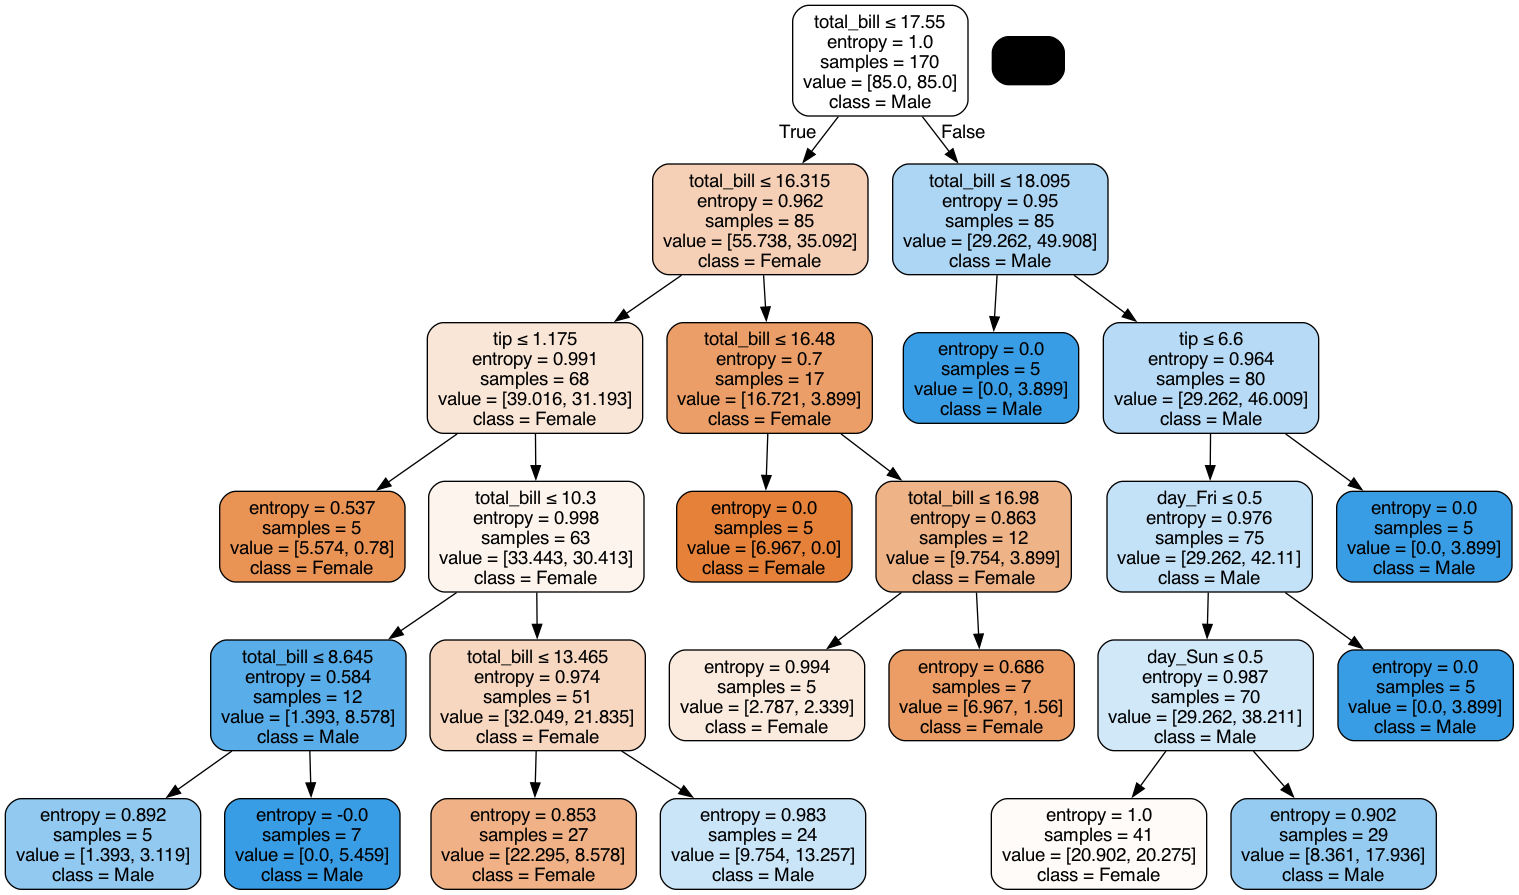

In [531]:
dot_data = StringIO()
export_graphviz(dt, out_file=dot_data,  
                filled=True, rounded=True,
                special_characters=True, feature_names = X.columns,
                class_names=["Female", "Male"])
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())  
graph.write_png('tips.png')
Image(graph.create_png())

Value - The weighted count of samples per class within this node. The value array are continuous because the Decision Tree was trained using the class_weight='balanced' parameter. The algorithm mathematically inflated the weight of the minority Female samples to equal the Male majority.

#### Task 1: Build at least 2 different classification models (from the previous session) on the penguins dataset, and tune them. The models should identify whether a penguin is male or female. Compare their results. Ensure that at least one of them is a Decision Tree.

## Feature importance from Decision Tree

Decision trees calculate feature importance using the Mean Decrease in Impurity (Gini or Entropy).

Every time a feature is used to split a node, the tree calculates how much that specific split reduced the chaos (entropy) in the data.

More about Mean Decrease in Impurity here: https://www.emergentmind.com/topics/mean-decrease-impurity-mdi

In [532]:
dt.feature_importances_

array([0.73308839, 0.13978295, 0.        , 0.        , 0.08154369,
       0.        , 0.04558497, 0.        ])

In [533]:
feature_importance_df = pd.DataFrame(X_train.columns, columns = ['features'])
feature_importance_df

,features
0,total_bill
1,tip
2,size
3,smoker_No
4,day_Fri
5,day_Sat
6,day_Sun
7,time_Dinner


In [534]:
feature_importance_df['importance'] = dt.feature_importances_
feature_importance_df.sort_values(by = 'importance', ascending = False)

,features,importance
0,total_bill,0.7331
1,tip,0.1398
4,day_Fri,0.0815
6,day_Sun,0.0456
2,size,0.0000
3,smoker_No,0.0000
5,day_Sat,0.0000
7,time_Dinner,0.0000


Look at the top of the DataFrame. total_bill has an importance score of 0.7331. This means that over 73% of the total reduction in entropy achieved by this entire model came from splits on the bill amount alone. tip is a distant second at 0.1398.

Native feature_importances_ is supported by Decision Trees, Random Forests, Gradient Boosting (XGBoost, LightGB).

K-Nearest Neighbors (KNN), Naive Bayes, and SVMs (with non-linear kernels like RBF) do not have a built-in way to rank features.

#### Task 2: Find the importance of the penguins' features from the Decision Tree model.

# Predicted probability using a Logistic Regression model

In [535]:
norm = MinMaxScaler()
X_norm_train = pd.DataFrame(norm.fit_transform(X_train), columns=X.columns)
X_norm_test = pd.DataFrame(norm.transform(X_test), columns=X.columns)

In [536]:
logreg = LogisticRegression(random_state=0, class_weight='balanced')
logreg.fit(X_norm_train, y_train)
y_predict = logreg.predict(X_norm_test)
y_train_estimated = logreg.predict(X_norm_train)

In [537]:
log_and_display_metrics('LogReg',logreg, X_norm_train, y_train, X_norm_test, y_test)

,Model,Train Acc,Test Acc,Train Prec,Test Prec,Train Rec,Test Rec,Train F1,Test F1,CV F1 Mean,CV F1 Std
0,DT tuned,0.6647,0.5000,0.5222,0.3590,0.7705,0.5385,0.6225,0.4308,0.4294,0.1133
1,LogReg,0.6118,0.6351,0.4603,0.4815,0.4754,0.5000,0.4677,0.4906,0.4517,0.0803


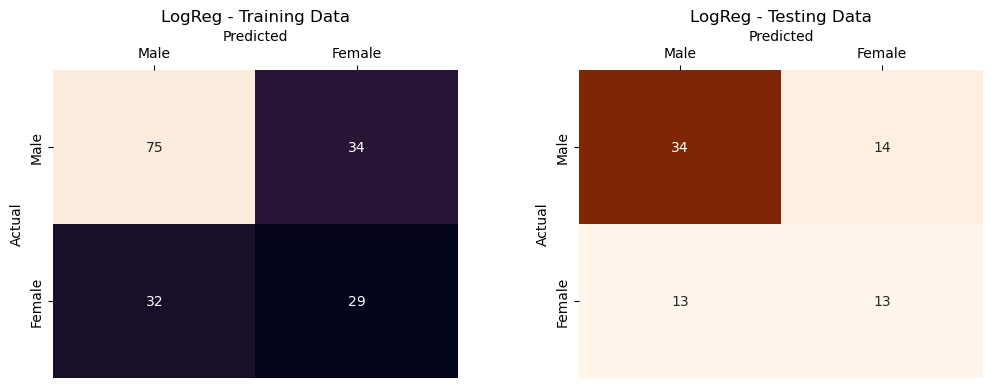

In [538]:
plot_confusion_matrices('LogReg', y_train, y_train_estimated, y_test, y_predict, labels=['Male', 'Female'])

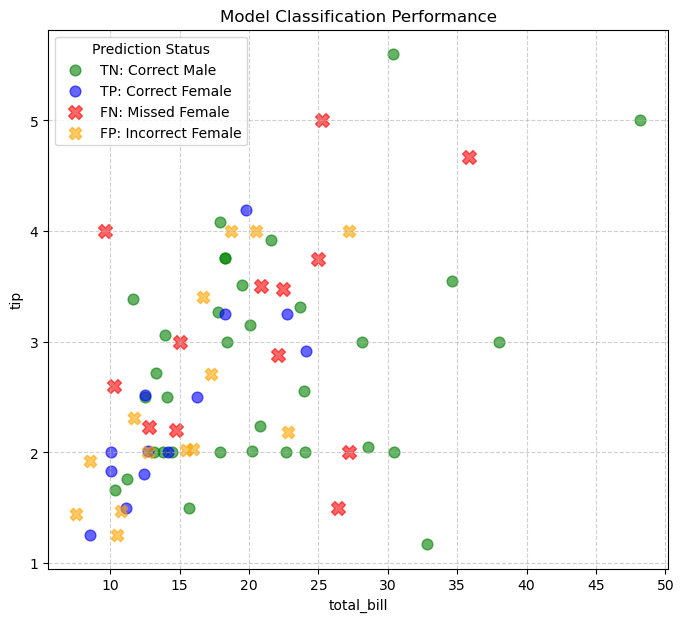

In [539]:
plot_the_test_results(X_test, y_test, y_predict)

## Predicted probability

Classification algorithms don’t actually predict categories like ‘Male’ or ‘Female’ directly. Instead, they calculate a probability between 0.0 and 1.0.

When we use .predict(), scikit-learn actually uses .predict_proba() behind the scenes and follows a simple rule: **if the probability is 0.5 or higher, it predicts the positive class**. Otherwise, it predicts the negative class. By looking at the raw probabilities ourselves, we can make our own decisions instead of relying on scikit-learn’s default.

In [540]:
# predict_proba() predicts class probabilities

y_predict_proba = logreg.predict_proba(X_norm_test)

In [541]:
y_predict_proba

array([[0.41007602, 0.58992398],
       [0.68885386, 0.31114614],
       [0.64515321, 0.35484679],
       [0.6472152 , 0.3527848 ],
       [0.3816158 , 0.6183842 ],
       [0.40276539, 0.59723461],
       [0.67795761, 0.32204239],
       [0.39453662, 0.60546338],
       [0.6510196 , 0.3489804 ],
       [0.43734491, 0.56265509],
       [0.64575557, 0.35424443],
       [0.6216057 , 0.3783943 ],
       [0.45323989, 0.54676011],
       [0.45973191, 0.54026809],
       [0.47655263, 0.52344737],
       [0.35797911, 0.64202089],
       [0.66419813, 0.33580187],
       [0.40344641, 0.59655359],
       [0.38638898, 0.61361102],
       [0.59551146, 0.40448854],
       [0.44304846, 0.55695154],
       [0.4992354 , 0.5007646 ],
       [0.41765307, 0.58234693],
       [0.64785466, 0.35214534],
       [0.3944168 , 0.6055832 ],
       [0.42879517, 0.57120483],
       [0.49104377, 0.50895623],
       [0.3863328 , 0.6136672 ],
       [0.67253077, 0.32746923],
       [0.38793784, 0.61206216],
       [0.

In [542]:
df_pred_proba = pd.DataFrame(y_predict_proba, columns = ['Prob_Female', 'Prob_Male'])
df_pred_proba

,Prob_Female,Prob_Male
0,0.4101,0.5899
1,0.6889,0.3111
2,0.6452,0.3548
3,0.6472,0.3528
4,0.3816,0.6184
...,...,...
69,0.3865,0.6135
70,0.4119,0.5881
71,0.3892,0.6108
72,0.4876,0.5124


In [543]:
df_pred_proba["predicted_label"] = y_predict
df_pred_proba

,Prob_Female,Prob_Male,predicted_label
0,0.4101,0.5899,Male
1,0.6889,0.3111,Female
2,0.6452,0.3548,Female
3,0.6472,0.3528,Female
4,0.3816,0.6184,Male
...,...,...,...
69,0.3865,0.6135,Male
70,0.4119,0.5881,Male
71,0.3892,0.6108,Male
72,0.4876,0.5124,Male


# Model evaluation: trade-offs

## Precision-Recall Curve

In [544]:
from sklearn.metrics import precision_recall_curve

In [545]:
y_test

178    Female
132    Female
226    Female
119    Female
186    Female
        ...  
56       Male
166      Male
73     Female
32     Female
75       Male
Name: sex, Length: 74, dtype: category
Categories (2, object): ['Male', 'Female']

In [546]:
precisions, recalls, thresholds = precision_recall_curve(y_test, 
                                                         y_predict_proba[:, 0], 
                                                         pos_label='Female') 

In [547]:
print(precisions, '\n', recalls, '\n', thresholds)

[0.35135135 0.35616438 0.36111111 0.36619718 0.35714286 0.36231884
 0.36764706 0.37313433 0.37878788 0.36923077 0.359375   0.36507937
 0.37096774 0.37704918 0.38333333 0.37288136 0.37931034 0.36842105
 0.375      0.38181818 0.38888889 0.37735849 0.36538462 0.35294118
 0.36       0.36734694 0.375      0.38297872 0.39130435 0.4
 0.40909091 0.39534884 0.38095238 0.3902439  0.4        0.41025641
 0.42105263 0.43243243 0.44444444 0.45714286 0.47058824 0.45454545
 0.46875    0.4516129  0.46666667 0.48275862 0.5        0.48148148
 0.5        0.48       0.5        0.52173913 0.5        0.47619048
 0.5        0.52631579 0.55555556 0.58823529 0.625      0.6
 0.57142857 0.61538462 0.58333333 0.63636364 0.6        0.66666667
 0.75       0.71428571 0.66666667 0.6        0.75       0.66666667
 0.5        0.         1.        ] 
 [1.         1.         1.         1.         0.96153846 0.96153846
 0.96153846 0.96153846 0.96153846 0.92307692 0.88461538 0.88461538
 0.88461538 0.88461538 0.88461538 0.846

The precision_recall_curve function checks every unique probability score from our model as a possible threshold. It calculates precision and recall for each one. We can put these results into a DataFrame to see how changing the threshold affects our metrics.

In [548]:
pr_df = pd.DataFrame([precisions, recalls, thresholds]).transpose()
pr_df.columns = ['precisions', 'recalls', 'thresholds']
pr_df

,precisions,recalls,thresholds
0,0.3514,1.0000,0.3127
1,0.3562,1.0000,0.3194
2,0.3611,1.0000,0.3580
3,0.3662,1.0000,0.3816
4,0.3571,0.9615,0.3863
...,...,...,...
70,0.7500,0.1154,0.6807
71,0.6667,0.0769,0.6889
72,0.5000,0.0385,0.7016
73,0.0000,0.0000,0.7031


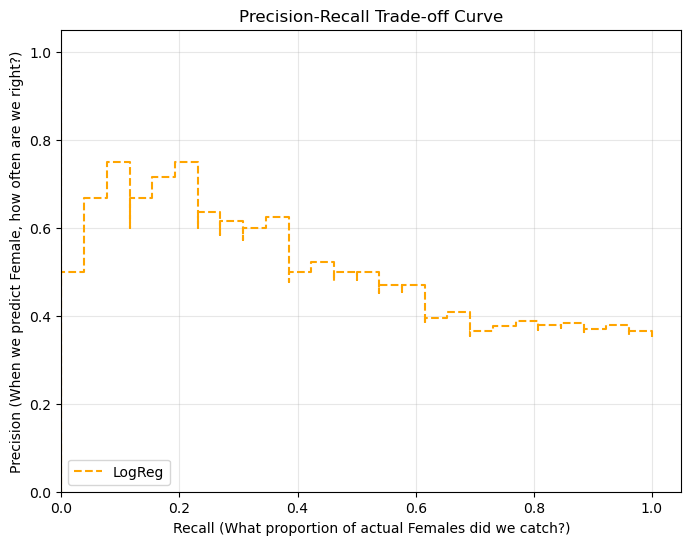

In [549]:
plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, drawstyle='steps-post', linestyle='--', color='orange', label='LogReg')

plt.title('Precision-Recall Trade-off Curve')
plt.xlabel('Recall (What proportion of actual Females did we catch?)')
plt.ylabel('Precision (When we predict Female, how often are we right?)')
plt.xlim([0.0, 1.05])
plt.ylim([0.0, 1.05])
plt.grid(True, alpha=0.3)
plt.legend(loc='lower left')
plt.show()

Scikit-Learn built-in function that displays the Precision-Recall curve.

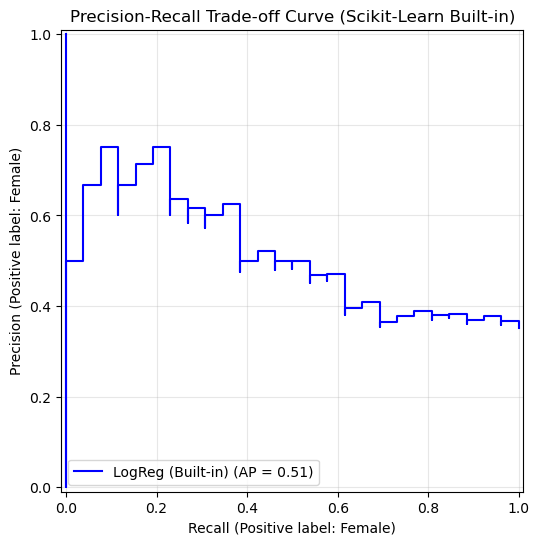

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

PrecisionRecallDisplay.from_estimator(
    logreg,               # The trained model
    X_norm_test,          # The test features
    y_test,               # The true test labels
    pos_label='Female',   # The target class
    name='LogReg',
    color='blue',
    ax=ax
)
plt.title('Precision-Recall Trade-off Curve (Scikit-Learn Built-in)')
plt.grid(True, alpha=0.3)
plt.show()

## ROC - AUC Curve

In [558]:
from sklearn.metrics import roc_auc_score

In [559]:
roc_auc_score(y_test, y_predict_proba[:, 1])

0.6274038461538461

There is a 62.74% probability that the model will rank a randomly chosen positive sample higher (give it a higher probability score) than a randomly chosen negative sample.

In [560]:
from sklearn.metrics import roc_curve

In [561]:
fpr1, tpr1, thresh1 = roc_curve(y_test, y_predict_proba[:,0], pos_label='Female')

In [562]:
print(fpr1, '\n', tpr1, '\n', thresh1)

[0.         0.02083333 0.02083333 0.04166667 0.04166667 0.08333333
 0.08333333 0.10416667 0.10416667 0.125      0.125      0.22916667
 0.22916667 0.27083333 0.27083333 0.29166667 0.29166667 0.35416667
 0.35416667 0.375      0.375      0.54166667 0.54166667 0.6875
 0.6875     0.75       0.75       0.77083333 0.77083333 0.85416667
 0.85416667 0.9375     0.9375     1.        ] 
 [0.         0.         0.11538462 0.11538462 0.23076923 0.23076923
 0.26923077 0.26923077 0.30769231 0.30769231 0.38461538 0.38461538
 0.46153846 0.46153846 0.5        0.5        0.53846154 0.53846154
 0.57692308 0.57692308 0.61538462 0.61538462 0.69230769 0.69230769
 0.80769231 0.80769231 0.84615385 0.84615385 0.88461538 0.88461538
 0.96153846 0.96153846 1.         1.        ] 
 [       inf 0.70312469 0.68071668 0.67795761 0.67177697 0.65117152
 0.6510196  0.64785466 0.6472152  0.64575557 0.64095102 0.61615926
 0.59551146 0.52613301 0.5119373  0.51086967 0.4992354  0.49104377
 0.48762105 0.47911615 0.4783161  0.4

In [563]:
pr_df = pd.DataFrame([fpr1[1:], tpr1[1:], thresh1[1:]]).transpose()
pr_df.columns = ['fpr1', 'tpr1', 'thresh1']
pr_df

,fpr1,tpr1,thresh1
0,0.0208,0.0000,0.7031
1,0.0208,0.1154,0.6807
2,0.0417,0.1154,0.6780
3,0.0417,0.2308,0.6718
4,0.0833,0.2308,0.6512
5,0.0833,0.2692,0.6510
6,0.1042,0.2692,0.6479
7,0.1042,0.3077,0.6472
8,0.1250,0.3077,0.6458
9,0.1250,0.3846,0.6410


For a threshold = 0.31, a very low probability, FPR and TPR are equal to 1, meaning that 100% of actual negative samples were incorrectly classified as positive(False Positive - very low Precision), and 100% of all actual positive samples were correctly classified as positive (True Positives - very high Recall).

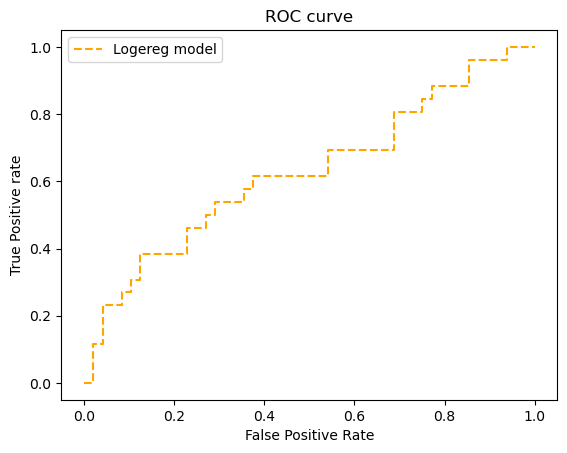

In [564]:
plt.plot(fpr1, tpr1, linestyle='--',color='orange', label='Logereg model')
plt.title('ROC curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')

Scikit-learn's built-in ROC-AUC tool.

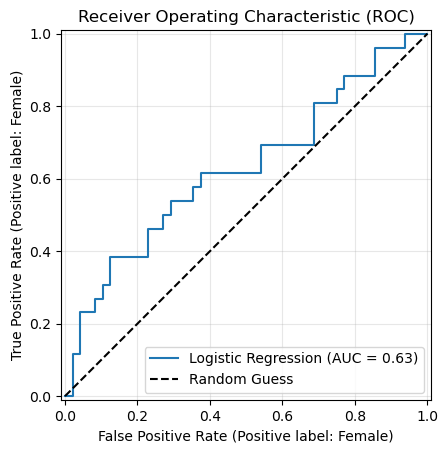

In [ ]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

RocCurveDisplay.from_estimator(
    logreg, 
    X_norm_test, 
    y_test, 
    pos_label='Female', 
    name='Logistic Regression'
)

# Add the 50/50 random guessing line for visual reference
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Random Guess')
plt.title('Receiver Operating Characteristic (ROC)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

#### Task 3: 
- Find the threshholds for precision and recall of the model based on the penguin dataset.
- Compute the roc_auc_score.

## Feature importance from Logistic Regression

In [567]:
coefficients = logreg.coef_[0]
coefficients

array([ 0.85181065,  0.45651819, -0.28607975, -0.11736003,  0.07351268,
        0.3206883 ,  0.56415042,  0.37810954])

In [568]:
feature_names = X_norm_train.columns

In [569]:
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Absolute_Importance': abs(coefficients)
})

In [570]:
importance_df

,Feature,Coefficient,Absolute_Importance
0,total_bill,0.8518,0.8518
1,tip,0.4565,0.4565
2,size,-0.2861,0.2861
3,smoker_No,-0.1174,0.1174
4,day_Fri,0.0735,0.0735
5,day_Sat,0.3207,0.3207
6,day_Sun,0.5642,0.5642
7,time_Dinner,0.3781,0.3781


Decision Trees show us how important a feature is, but Logistic Regression also shows us whether a feature increases or decreases the chance of a certain outcome.

Since we scaled our data earlier with MinMaxScaler, we can now compare these coefficients fairly.

* A positive coefficient means that as this feature increases, the model is more likely to predict our target class, which is ‘Female’.
* If a coefficient is negative, increasing that feature makes the model more likely to predict the other class, which is ‘Male’.

In [571]:
importance_df = importance_df.sort_values(by='Absolute_Importance', ascending=False)
importance_df

,Feature,Coefficient,Absolute_Importance
0,total_bill,0.8518,0.8518
6,day_Sun,0.5642,0.5642
1,tip,0.4565,0.4565
7,time_Dinner,0.3781,0.3781
5,day_Sat,0.3207,0.3207
2,size,-0.2861,0.2861
3,smoker_No,-0.1174,0.1174
4,day_Fri,0.0735,0.0735


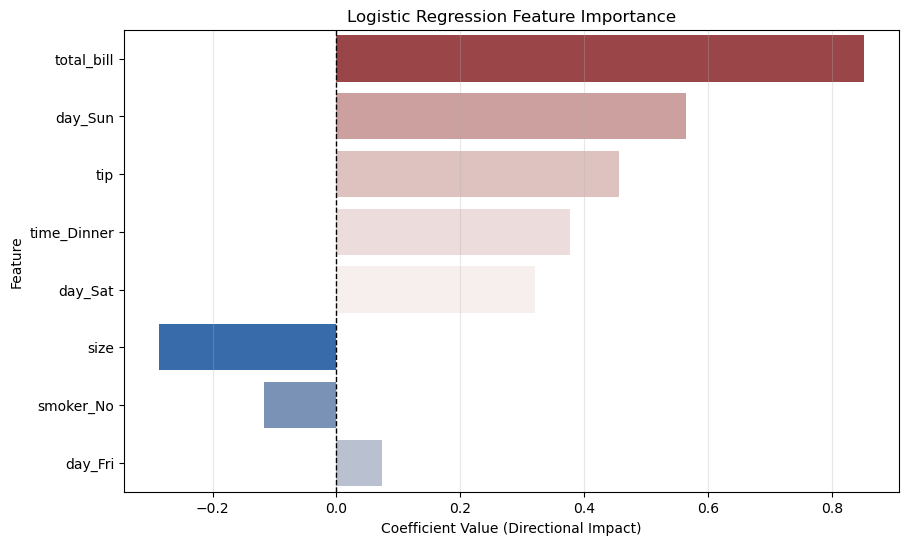

In [572]:
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x='Coefficient', y='Feature', hue='Coefficient', palette='vlag', legend=False)

plt.title('Logistic Regression Feature Importance')
plt.xlabel('Coefficient Value (Directional Impact)')
plt.ylabel('Feature')
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.grid(True, axis='x', alpha=0.3)
plt.show()

# Multiclass

#### Task 4: Change the target. Now our model will predict the species of penguins. 
- Train the model
- Find out the feature importance
- Make predictions for the test sample
- Visualize the confusion matrix for test data and post it in the chat
- Compute the accuracy, precision and recall

**Precision and recall require an additional parameter: average.**

Average parameter is required for multiclass/multilabel targets. {‘micro’, ‘macro’, ‘samples’, ‘weighted’, ‘binary’} or None, default=’binary’

- 'micro':
Calculate metrics globally by counting the total true positives, false negatives and false positives.

- 'macro':
Calculate metrics for each label, and find their unweighted mean. This does not take label imbalance into account.

Documentation for recall: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html
